---
# Instructions

- Exam 2 - Applied is worth **162 points**. 
- Please strive for clarity and organization.
- **AI Usage**:
   - The use of AI to generate complete answers is strictly **prohibited**. AI may only be used for debugging purposes.
- **Due Date: Friday, November 20, 2026, by 11:59 PM.**
---

# Exercise 1 (5 points)

Consider the below Python code snipett.

```
import pandas as pd

data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, '35'],
    'Salary': [50000, 60000, 70000]
}

df = pd.DataFrame(data)

df['Age'].mean()
print(f"The average age is {df['Age'].mean()}")

{
	"name": "TypeError",
	"message": "unsupported operand type(s) for +: 'int' and 'str'",
	"stack": "---------------------------------------------------------------------------
TypeError                                 Traceback (most recent call last)
/tmp/ipykernel_134744/376740308.py in <module>
      9 df = pd.DataFrame(data)
     10 
---> 11 df['Age'].mean()
     12 print(f\"The average age is {df['Age'].mean()}\")

~/.local/lib/python3.10/site-packages/pandas/core/series.py in mean(self, axis, skipna, numeric_only, **kwargs)
   6547         **kwargs,
   6548     ):
-> 6549         return NDFrame.mean(self, axis, skipna, numeric_only, **kwargs)
   6550 
   6551     @doc(make_doc(\"median\", ndim=1))

~/.local/lib/python3.10/site-packages/pandas/core/generic.py in mean(self, axis, skipna, numeric_only, **kwargs)
  12418         **kwargs,
  12419     ) -> Series | float:
> 12420         return self._stat_function(
  12421             \"mean\", nanops.nanmean, axis, skipna, numeric_only, **kwargs
  12422         )

~/.local/lib/python3.10/site-packages/pandas/core/generic.py in _stat_function(self, name, func, axis, skipna, numeric_only, **kwargs)
  12375         validate_bool_kwarg(skipna, \"skipna\", none_allowed=False)
  12376 
> 12377         return self._reduce(
  12378             func, name=name, axis=axis, skipna=skipna, numeric_only=numeric_only
  12379         )

~/.local/lib/python3.10/site-packages/pandas/core/series.py in _reduce(self, op, name, axis, skipna, numeric_only, filter_type, **kwds)
   6455                     \"with non-numeric dtypes.\"
   6456                 )
-> 6457             return op(delegate, skipna=skipna, **kwds)
   6458 
   6459     @Appender(make_doc(\"any\", ndim=1))

~/.local/lib/python3.10/site-packages/pandas/core/nanops.py in f(values, axis, skipna, **kwds)
    145                     result = alt(values, axis=axis, skipna=skipna, **kwds)
    146             else:
--> 147                 result = alt(values, axis=axis, skipna=skipna, **kwds)
    148 
    149             return result

~/.local/lib/python3.10/site-packages/pandas/core/nanops.py in new_func(values, axis, skipna, mask, **kwargs)
    402             mask = isna(values)
    403 
--> 404         result = func(values, axis=axis, skipna=skipna, mask=mask, **kwargs)
    405 
    406         if datetimelike:

~/.local/lib/python3.10/site-packages/pandas/core/nanops.py in nanmean(values, axis, skipna, mask)
    717 
    718     count = _get_counts(values.shape, mask, axis, dtype=dtype_count)
--> 719     the_sum = values.sum(axis, dtype=dtype_sum)
    720     the_sum = _ensure_numeric(the_sum)
    721 

~/.local/lib/python3.10/site-packages/numpy/core/_methods.py in _sum(a, axis, dtype, out, keepdims, initial, where)
     47 def _sum(a, axis=None, dtype=None, out=None, keepdims=False,
     48          initial=_NoValue, where=True):
---> 49     return umr_sum(a, axis, dtype, out, keepdims, initial, where)
     50 
     51 def _prod(a, axis=None, dtype=None, out=None, keepdims=False,

TypeError: unsupported operand type(s) for +: 'int' and 'str'"
}
```

Explain what is/are wrong with the code and fix it using `pandas` commands. Please, be specific.

In [2]:
import pandas as pd

data = {
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, '35'],
    'Salary': [50000, 60000, 70000]
}

df = pd.DataFrame(data)

# Convert Age values to numbers
df['Age'] = pd.to_numeric(df['Age'])

# Calculate and print the average age
print(f"The average age is {df['Age'].mean()}")

The average age is 30.0


The problem with the code is that the Age column contains both integers and a string. The values 25 and 30 are integers, but '35' is a string because it has quotation marks. When pandas tries to calculate the average, it produces a TypeError because it cannot add integers and strings together.

To fix this, I used pd.to_numeric(df['Age']) to convert the Age column into numeric values. After converting the data, pandas can calculate the average correctly, which is 30.0

# Exercise 2 

Consider the below data dictionary.

```
data = {'x': [1, 1, 1, 1, 1, 5], 
        'y': [5.2, 6.2, 6.6, 7, 7.4, 10]}
```

### Exercise 2(a) (3 points)

Using the appropriate commands, create a data-frame called `df` using the `data` dictionary.

In [3]:
data = {'x': [1, 1, 1, 1, 1, 5], 
        'y': [5.2, 6.2, 6.6, 7, 7.4, 10]}

df = pd.DataFrame(data)
print(df)

   x     y
0  1   5.2
1  1   6.2
2  1   6.6
3  1   7.0
4  1   7.4
5  5  10.0


### Exercise 2(b) (3 points)

Using the appropriate command, compute the correlation between `x` and `y`.

In [5]:
df['x'].corr(df['y'])

np.float64(0.8853280002440871)

### Exercise 2(c) (3 points)

Standard thresholds for the correlation (r) are the following:

- 0 < |r| < 0.3 -> weak correlation.
- 0.3 < |r| < 0.7 -> moderate correlation.
- 0.7 < |r| < 1 -> strong correlation.

Notice that || represents absolute value. Based on the three rules of thumb mentioned above, what can we conclude about the correlation between `x` and `y`?

The correlation between x and y is approximately 0.8853, which indicates a strong postive correlation based on the guidelines provided. This means that as x increases, y also tends to increase.

### Exercise 2(d) (5 points)

Create a scatter plot to visualize the relationship between `x` and `y`. Describe the features of the plot. Does your conclusion from part 2(c) align with what you observe in the scatter plot? What do you believe contributes to the high correlation value?

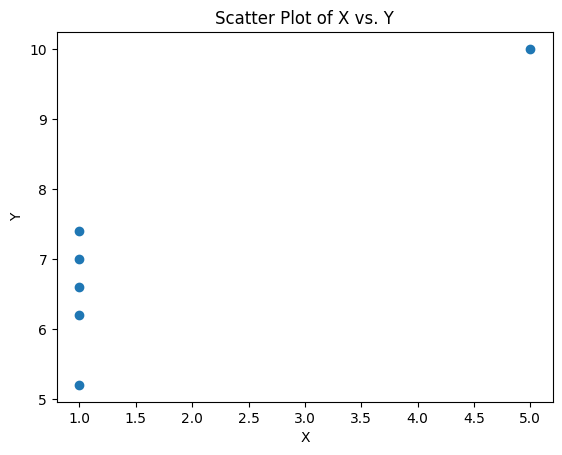

In [6]:
import matplotlib.pyplot as plt

plt.scatter(df['x'], df['y'])
plt.title('Scatter Plot of X vs. Y')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

The scatter plot shows that most of the data points are grouped together at x = 1, while one point is farther away at x = 5. The correlation is strong and positive, but this seems to be influenced by the one point that is separated from the others. This shows why it is important to look at a scatter plot instead of relying only on the correlation number.

# Exercise 3

Consider the `train.csv` data file, which is a synthetic dataset generated from a depression survey conducted in India. In this exercise, we will explore this data. Below is a brief description of each of the features included in the data file:

- `Name`: The name of the survey participant.
- `Gender`: The gender of the survey participant.
- `Age`: The age of the survey participant.
- `City`: The city where the survey participant resides.
- `Working Professional`:  Indicates whether the survey participant is a working professional or a student.
- `Profession`: The profession of the survey participant.
- `Academic Pressure`: An integer from 1 to 5 representing the academic pressure experienced by the student.
- `Work Pressure`: An integer from 1 to 5 representing the work pressure experienced by the professional participant.
- `CGPA`: The participant's academic grade point average.
- `Study Satisfaction`: An integer from 1 to 5 indicating the participant's satisfaction with their studies. 
- `Job Satisfaction`: An integer from 1 to 5 indicating the participant's job satisfaction.
- `Sleep Duration`: The amount of sleep the survey participant gets.
- `Dietary Habits`: A label describing the participant's dietary habits.
- `Degree`: The academic degree of the survey participant.
- `Have you ever had suicidal thoughts?`: Indicates whether the survey participant has experienced suicidal thoughts.
- `Work/Study Hours`: The number of hours the participant spends working or studying.
- `Financial Stress`: An integer from 1 to 5 representing the level of financial stress.
- `Family History of Mental Illness`: Indicates whether there is a history of mental illness in the family.
- `Depression`: Indicates whether the survey participant is experiencing depression.


### Exercise 3(a) (3 points)

Import the `pandas` libraries, read the `train.csv`, and create a data-frame called `df`. Report the shape of `df`.

In [8]:
import pandas as pd

df = pd.read_csv('train.csv')

print(df.shape)

(140700, 20)


### Exercise 3(b) (2 points)

Using the appropriate commands, report the frequency table of `Depression`.

In [9]:
df['Depression'].value_counts()

Depression
0    115133
1     25567
Name: count, dtype: int64

### Exercise 3(c) (3 points)

Are males more depressed than females? Use the appropriate commands to answer the question.

In [10]:
df.groupby('Gender')['Depression'].mean() * 100

Gender
Female    17.823708
Male      18.455024
Name: Depression, dtype: float64

Yes, males have a slightly higher depression rate than females. About 18.46% of males reported depression compared to 17.82% of females. However, the difference is small.

### Exercise 3(d) (3 points)

Are working professionals more depressed than students? Use the appropriate commands to answer the question.

In [11]:
df.groupby('Working Professional or Student')['Depression'].mean() * 100

Working Professional or Student
Student                 58.549873
Working Professional     8.183583
Name: Depression, dtype: float64

No, students have a much higher reported depression rate than working professionals. About 58.55% of students reported depression compared to only 8.18% of working professionals. This shows a large difference between the two groups in this dataset.

### Exercise 3(e) (5 points)

Is there a relationship between `Age` and `Depression`? Use the appropriate commands to create a visualization to answer the question.

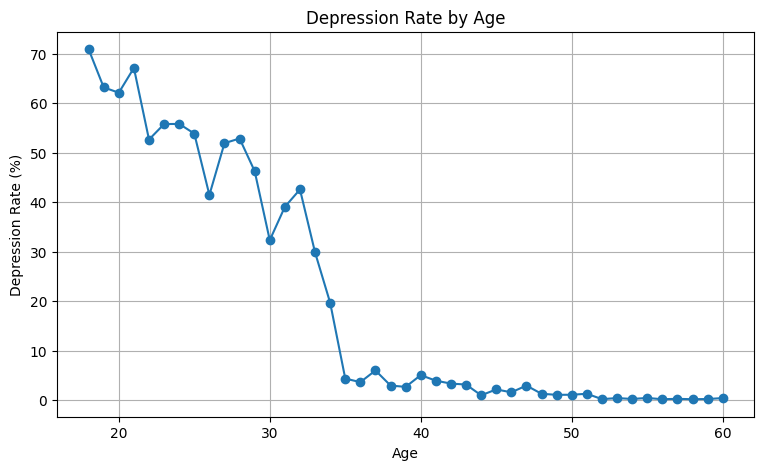

In [12]:
age_depression = df.groupby('Age')['Depression'].mean() * 100

age_depression.plot(
    kind='line',
    marker='o',
    figsize=(9, 5),
    title='Depression Rate by Age'
)

plt.xlabel('Age')
plt.ylabel('Depression Rate (%)')
plt.grid(True)
plt.show()

The graph shows a relationship between age and depression. Younger participants have higher reported depression rates, while older participants have lower rates. The depression rate generally decreases as age increases, especially after age 30.

### Exercise 3(f) (3 points)

Does you answer from part 3(e) agree with your answer from part 3(d)?

Yes, the results agree. In Exercise 3(d), students had a much higher reported depression rate than working professionals. The graph in Exercise 3(e) also shows that younger participants have higher depression rates. Since students are generally younger, these results are consistent with each other.

### Exercise 3(g) (3 points)

What percentage of individuals with a family history of mental illness report depression? Use the appropriate commands to answer the question.

In [13]:
df[df['Family History of Mental Illness'] == 'Yes']['Depression'].mean() * 100

np.float64(18.81130079208487)

About 18.81% of individuals with a family history of mental illness reported depression in this dataset.

### Exercise 3(h) (4 points)

What is the relationship between sleep duration and depression? Use the appropriate commands to answer the question.

In [15]:
df.groupby('Sleep Duration')['Depression'].mean() * 100

sleep_summary = df.groupby('Sleep Duration')['Depression'].agg(
    Count='count',
    Depression_Rate='mean'
)

sleep_summary['Depression_Rate'] *= 100

print(sleep_summary.to_string())

                   Count  Depression_Rate
Sleep Duration                           
1-2 hours              1         0.000000
1-3 hours              1         0.000000
1-6 hours              4         0.000000
10-11 hours            2       100.000000
10-6 hours             1         0.000000
2-3 hours              5        20.000000
3-4 hours             12         8.333333
3-6 hours              1         0.000000
35-36 hours            1         0.000000
4-5 hours              7        14.285714
4-6 hours              5        20.000000
40-45 hours            1       100.000000
45                     2         0.000000
45-48 hours            1         0.000000
49 hours               1         0.000000
5-6 hours          32142        16.557775
55-66 hours            1       100.000000
6-7 hours              8        25.000000
6-8 hours              4         0.000000
7-8 hours          36969        17.833861
8 hours                1       100.000000
8-9 hours              2        50

The results show that depression rates vary depending on sleep duration. For example, about 16.56% of participants sleeping 5–6 hours reported depression, compared to 17.83% of those sleeping 7–8 hours. However, some categories have very few participants or unusual values, making it difficult to determine a clear relationship between sleep duration and depression.

### Exercise 3(i) (3 points)

Based on your analysis from part 3(h), is there anything that needs to be addressed to draw better insights? Please, be specific.

To get better results, I would first clean the Sleep Duration column because some values are unrealistic or incorrectly entered, such as 40–45 hours and 55–66 hours. I would also check categories with very few participants because their percentages can be misleading. After cleaning the data, I would group sleep durations into consistent categories and compare the depression rates again.

### Exercise 3(j) (4 points)

When analyzing the `Working Professional or Student` and `Profession` categories, you will notice that some students have a profession listed instead of a missing value. How should you approach this in your analysis?

I would first check the records where someone is listed as a student but also has a profession. This doesn't always mean the data is incorrect because some students may also have jobs. I would look for patterns and check how the information was collected before making changes. I wouldn't automatically delete or change those records because that could remove useful information from the dataset.

### Exercise 3(k) (5 points)

Is there a relationship between financial streess and depression? Use the appropriate commands to create a visualization to answer the question.

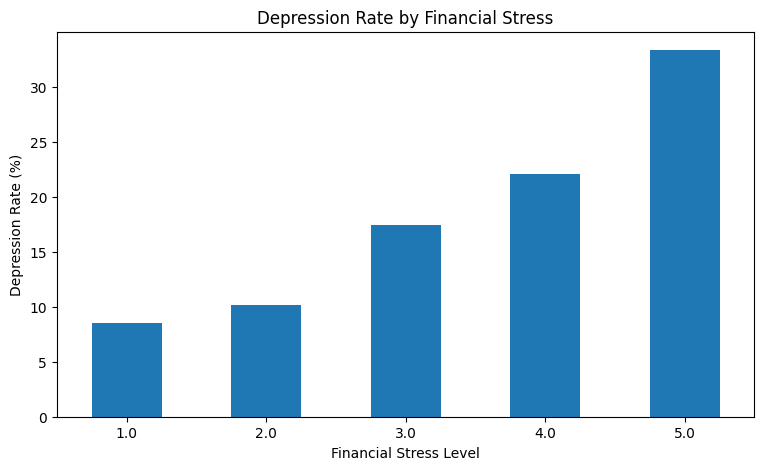

In [17]:
financial_stress = df.groupby('Financial Stress')['Depression'].mean() * 100

financial_stress.plot(
    kind='bar',
    figsize=(9, 5),
    title='Depression Rate by Financial Stress'
)

plt.xlabel('Financial Stress Level')
plt.ylabel('Depression Rate (%)')
plt.xticks(rotation=0)
plt.show()

Yes, there is a relationship between financial stress and depression. The graph shows that as financial stress increases, the percentage of people reporting depression also increases. For example, about 8% of participants with the lowest financial stress reported depression, compared to approximately 33% of those with the highest financial stress. This suggests that higher financial stress is associated with higher depression rates.

### Exercise 3(l) (4 points)

What is the relationship between dietary habits and depression? Use the appropriate commands to answer the question.

In [18]:
df.groupby('Dietary Habits')['Depression'].agg(
    Count='count',
    Depression_Rate='mean'
).assign(
    Depression_Rate=lambda x: x['Depression_Rate'] * 100    
)

,Count,Depression_Rate
Dietary Habits,,
1.0,1,100.000000
2,1,0.000000
3,1,100.000000
BSc,1,0.000000
Class 12,1,0.000000
Electrician,1,0.000000
Gender,1,0.000000
Healthy,44741,11.803491
Hormonal,1,0.000000


The results show that dietary habits are related to depression in this dataset. Participants with unhealthy dietary habits had the highest reported depression rate at 26.05%, followed by moderate dietary habits at 16.56% and healthy dietary habits at 11.80%. This suggests that unhealthy dietary habits are associated with higher reported depression rates.

### Exercise 3(m) (3 points)

Based on your analysis from part 3(l), is there anything that needs to be addressed to draw better insights? Please, be specific.

To get better insights, I would first clean the Dietary Habits column because some values do not belong there, such as Electrician, Gender, and Class 12. I would check these records and correct them if possible or mark them as missing if the correct information is unknown. I would also focus on the main categories of Healthy, Moderate, and Unhealthy because they have enough participants for a more reliable comparison.

# Exercise 4 (20 points)

A data-engineering team wants a robust function that loads the survey data (`train.csv`) and fails **predictably and informatively** when something goes wrong. The function must be able to deal with the following situations: the file does not exist, the file is empty, and the file is missing some of the columns the analysis needs.

### Exercise 4(a) (8 points)

Define a custom exception hierarchy: a base class `SurveyError(Exception)` and a subclass `MissingColumnsError(SurveyError)` that stores the list of missing columns. Then write a function `load_survey(path, required_columns)` that:

- reads the file with `pandas`;
- converts `FileNotFoundError` and `pandas.errors.EmptyDataError` into a `SurveyError` with a clear message, **preserving the original exception** as the cause;
- raises `MissingColumnsError` if any of `required_columns` is not in the data;
- uses `try`/`except`/`else`/`finally` appropriately (the `finally` block should always print which file was attempted).

In [25]:
import pandas as pd

class SurveyError(Exception):
    pass

class MissingColumnsError(SurveyError):
    def __init__(self, missing_columns):
        self.missing_columns = missing_columns
        super().__init__(f"Missing required columns: {missing_columns}")

def load_survey(path, required_columns):
    try:
        df = pd.read_csv(path)

    except (FileNotFoundError, pd.errors.EmptyDataError) as err:
        raise SurveyError(f"Could not load {path}: {err}") from err

    else:
        missing = [
            col for col in required_columns
            if col not in df.columns
        ]

        if missing:
            raise MissingColumnsError(missing)

        return df

    finally:
        print(f"Attempted to load: {path}")

### Exercise 4(b) (8 points)

Test `load_survey` in four scenarios: (i) a valid call with `required_columns=['Age', 'Depression']`, (ii) a path that does not exist, (iii) an empty file, and (iv) a valid file with `required_columns=['Age', 'Salary']`. Each failure must be caught with the **most specific** exception possible, and the message (and, when present, the original cause) must be printed.

In [26]:
# Test 1: Valid file
try:
    result = load_survey(
        'train.csv',
        required_columns=['Age', 'Depression']
    )
    print("Success! Data loaded.")
    print(result.shape)

except SurveyError as err:
    print(f"Error: {err}")

# Test 2: Missing file
try:
    load_survey(
        'missing_file.csv',
        required_columns=['Age', 'Depression']
    )

except SurveyError as err:
    print(f"Error: {err}")
    print(f"Original cause: {err.__cause__}")

# Test 3: Empty file

# Create an empty CSV file
with open('empty.csv', 'w') as file:
    pass

try:
    load_survey(
        'empty.csv',
        required_columns=['Age', 'Depression']
    )

except SurveyError as err:
    print(f"Error: {err}")
    print(f"Original cause: {err.__cause__}")

# Test 4: Missing required column
try:
    load_survey(
        'train.csv',
        required_columns=['Age', 'Salary']
    )

except MissingColumnsError as err:
    print(f"Error: {err}")
    print(f"Missing columns: {err.missing_columns}")

Attempted to load: train.csv
Success! Data loaded.
(140700, 20)
Attempted to load: missing_file.csv
Error: Could not load missing_file.csv: [Errno 2] No such file or directory: 'missing_file.csv'
Original cause: [Errno 2] No such file or directory: 'missing_file.csv'
Attempted to load: empty.csv
Error: Could not load empty.csv: No columns to parse from file
Original cause: No columns to parse from file
Attempted to load: train.csv
Error: Missing required columns: ['Salary']
Missing columns: ['Salary']


### Exercise 4(c) (4 points)

Explain (i) why `raise SurveyError(...) from err` is better than simply raising a new exception inside the `except` block, and (ii) why wrapping the whole function body in a bare `except:` that returns `None` would be a bad design.

Using `raise SurveyError(...) from err` is better because it keeps the original error connected to the new error. This makes it easier to understand what went wrong and find the problem.

Using a bare `except:` that returns `None` is bad because it hides errors instead of explaining them. This makes debugging harder, and the program might continue running without knowing something went wrong.

# Exercise 5 (16 points)

In a scheduled pipeline nobody watches the screen, so the only evidence of what happened is the **log**. In the `train.csv` data, the `Sleep Duration` column contains four standard labels (`'Less than 5 hours'`, `'5-6 hours'`, `'7-8 hours'`, `'More than 8 hours'`) plus a few non-standard ones (e.g., `'No'`, `'3-4 hours'`).

### Exercise 5(a) (5 points)

Using the `logging` module (not `print`), configure the logging system so that every message is written **both** to the console and to the file `survey_pipeline.log`, with a format that includes the timestamp, logger name, severity level, and message. Use a named logger called `survey.cleaning`.

In [40]:
import logging

# Create a named logger
logger = logging.getLogger("survey.cleaning")
logger.setLevel(logging.DEBUG)

# Set the message format
formatter = logging.Formatter(
    '%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)

# Remove old handlers
for handler in logger.handlers[:]:
    logger.removeHandler(handler)
    handler.close()

# Send messages to the console
console_handler = logging.StreamHandler()
console_handler.setFormatter(formatter)

# Save messages to a file
file_handler = logging.FileHandler("survey_pipeline.log")
file_handler.setFormatter(formatter)

# Add the new handlers
logger.addHandler(console_handler)
logger.addHandler(file_handler)
logger.propagate = False

logger.info("Logging system is ready.")

2026-11-20 12:08:10,753 - survey.cleaning - INFO - Logging system is ready.


### Exercise 5(b) (8 points)

Write a function `clean_sleep_duration(df)` that replaces every non-standard `Sleep Duration` label with a missing value and returns a **new** data-frame. The function must log: an `INFO` message at start and at the end (with the number of valid rows), a `WARNING` with the number of affected rows if non-standard labels are found, and a `DEBUG` message listing the offending labels. If the column does not exist, log the problem (including the traceback) with the `ERROR` level and re-raise the exception. Call the function with `train.csv` and then with a data-frame that does not contain the column.

In [41]:
valid_sleep = [
    'Less than 5 hours',
    '5-6 hours',
    '7-8 hours',
    'More than 8 hours'
]

def clean_sleep_duration(df):
    logger.info("Starting sleep duration cleaning")

    try:
        cleaned_df = df.copy()

        # Check that the column exists
        if 'Sleep Duration' not in cleaned_df.columns:
            raise KeyError("Sleep Duration column is missing")

        # Find non-standard sleep labels
        invalid = (
            cleaned_df['Sleep Duration'].notna()
            & ~cleaned_df['Sleep Duration'].isin(valid_sleep)
        )

        invalid_count = invalid.sum()
        invalid_labels = cleaned_df.loc[
            invalid, 'Sleep Duration'
        ].unique().tolist()

        if invalid_count > 0:
            logger.warning(
                f"Found {invalid_count} rows with non-standard sleep labels"
            )
            logger.debug(f"Invalid labels: {invalid_labels}")

        # Replace non-standard labels with missing values
        cleaned_df.loc[invalid, 'Sleep Duration'] = pd.NA

        logger.info(
            f"Cleaning finished. Valid rows: "
            f"{cleaned_df['Sleep Duration'].notna().sum()}"
        )

        return cleaned_df

    except KeyError:
        logger.exception("Sleep Duration column is missing")
        raise

# Test with the survey dataset
cleaned_df = clean_sleep_duration(df)

# Check the remaining sleep duration categories
print(cleaned_df['Sleep Duration'].value_counts(dropna=False))

# Test with a missing Sleep Duration column
test_df = pd.DataFrame({
    'Age': [20, 25, 30]
})

try:
    clean_sleep_duration(test_df)
except KeyError as err:
    print(f"Caught expected error: {err}")

2026-11-20 12:08:33,607 - survey.cleaning - INFO - Starting sleep duration cleaning
2026-11-20 12:08:33,628 - survey.cleaning - WARNING - Found 79 rows with non-standard sleep labels
2026-11-20 12:08:33,628 - survey.cleaning - DEBUG - Invalid labels: ['Sleep_Duration', '1-2 hours', '6-8 hours', '4-6 hours', '6-7 hours', '10-11 hours', '8-9 hours', '40-45 hours', '9-11 hours', '2-3 hours', '3-4 hours', 'Moderate', '55-66 hours', '4-5 hours', '9-6 hours', '1-3 hours', 'Indore', '45', '1-6 hours', '35-36 hours', '8 hours', 'No', '10-6 hours', 'than 5 hours', '49 hours', 'Unhealthy', 'Work_Study_Hours', '3-6 hours', '45-48 hours', '9-5', 'Pune', '9-5 hours']
2026-11-20 12:08:33,633 - survey.cleaning - INFO - Cleaning finished. Valid rows: 140621
2026-11-20 12:08:33,640 - survey.cleaning - INFO - Starting sleep duration cleaning
2026-11-20 12:08:33,640 - survey.cleaning - ERROR - Sleep Duration column is missing
Traceback (most recent call last):
  File "/var/folders/pv/zcbj60bs18g8nc18wwh6

Sleep Duration
Less than 5 hours    38784
7-8 hours            36969
More than 8 hours    32726
5-6 hours            32142
<NA>                    79
Name: count, dtype: int64
Caught expected error: 'Sleep Duration column is missing'


### Exercise 5(c) (3 point)

Show the content of the log file and explain why, in the above exercise, `logger.exception(...)` is used instead of `print(...)`.

In [42]:
import os

print("Current folder:", os.getcwd())
print("Log file exists:", os.path.exists("survey_pipeline.log"))

with open("survey_pipeline.log", "r") as file:
    print(file.read())

Current folder: /Users/daisycabriales/Downloads/DATA-500
Log file exists: True
2026-11-20 12:06:09,355 - survey.cleaning - INFO - Logging system is ready.
2026-11-20 12:08:02,770 - survey.cleaning - INFO - Logging system is ready.
2026-11-20 12:08:07,372 - survey.cleaning - INFO - Logging system is ready.
2026-11-20 12:08:10,753 - survey.cleaning - INFO - Logging system is ready.
2026-11-20 12:08:33,607 - survey.cleaning - INFO - Starting sleep duration cleaning
2026-11-20 12:08:33,628 - survey.cleaning - WARNING - Found 79 rows with non-standard sleep labels
2026-11-20 12:08:33,628 - survey.cleaning - DEBUG - Invalid labels: ['Sleep_Duration', '1-2 hours', '6-8 hours', '4-6 hours', '6-7 hours', '10-11 hours', '8-9 hours', '40-45 hours', '9-11 hours', '2-3 hours', '3-4 hours', 'Moderate', '55-66 hours', '4-5 hours', '9-6 hours', '1-3 hours', 'Indore', '45', '1-6 hours', '35-36 hours', '8 hours', 'No', '10-6 hours', 'than 5 hours', '49 hours', 'Unhealthy', 'Work_Study_Hours', '3-6 hours

I used `logger.exception()` instead of `print()` because it records the error message along with the full traceback. This helps me understand where the error happened and what caused it. Logging also saves the information to a file, making it easier to review errors later, especially when the program runs automatically.

# Exercise 6 (14 points)

Consider the below Python code snippet, which is intended to return the moving average of a list of numbers (the average of each block of `window` consecutive values).

```
def moving_average(values, window=3, result=[]):
    for i in range(len(values) - window):
        result.append(sum(values[i:i + window]) / window)
    return result

print(moving_average([1, 2, 3, 4, 5]))
print(moving_average([10, 20, 30, 40]))

[2.0, 3.0]
[2.0, 3.0, 20.0]
```

The expected output is `[2.0, 3.0, 4.0]` and `[20.0, 30.0]`.

### Exercise 6(a) (6 points)

The code does not raise an error, but it produces wrong results. Identify the bugs and explain how you found them.

I found two bugs in the function. The first bug is that the loop stops too early because it uses `range(len(values) - window)` instead of `range(len(values) - window + 1)`. This causes the function to leave out the last moving average.

The second bug is using `result=[]` as a default argument. Python reuses the same list every time the function is called, so the second result includes values from the first call.

I found these bugs by comparing the actual output with the expected output and noticing that the first result was missing a value and the second result contained extra values.

### Exercise 6(b) (8 points)

Fix the function. Validate its inputs (raise an informative `ValueError` if `window` is not a positive integer or is larger than the number of values) and add an `assert` as a sanity check on the length of the output. Finally, show that the function now produces the expected results with additional `assert` statements, including an edge case.

In [48]:
def moving_average(values, window=3):
    # Check that window is a positive integer
    if type(window) is not int or window <= 0:
        raise ValueError("Window must be a positive integer")

    # Check that window is not larger than the list
    if window > len(values):
        raise ValueError("Window cannot be larger than the list")

    # Create a new result list each time
    result = []

    # Calculate the moving averages
    for i in range(len(values) - window + 1):
        average = sum(values[i:i + window]) / window
        result.append(average)

    return result

# Test the first expected result
assert moving_average([1, 2, 3, 4, 5]) == [2.0, 3.0, 4.0]

# Test the second expected result
assert moving_average([10, 20, 30, 40]) == [20.0, 30.0]

# Edge case: Window size of 1
assert moving_average([1, 2, 3], 1) == [1.0, 2.0, 3.0]

# Edge case: Window equals list length
assert moving_average([2, 4, 6], 3) == [4.0]

print("All tests passed!")

# Test invalid window sizes
for invalid_window in [0, -1, 2.5, 10]:
    try:
        moving_average([1, 2, 3], invalid_window)
        assert False, "Expected a ValueError"
    except ValueError:
        pass

print("Invalid window tests passed!")

All tests passed!
Invalid window tests passed!


# Exercise 7 (16 points)

Consider the below Python code snippet.

```
import os,sys
import pandas as pd
from typing import *

def CalcBMI(Weight,Height,round_to = 2):
    try:
        bmi=Weight/(Height**2)
        if bmi == None:
            return None
        return round(bmi,round_to)
    except:
        return None
```

### Exercise 7(a) (8 points)

Without running the code, list at least **five** problems that a formatter, a linter, or a type checker would report. For each problem, indicate the tool category (formatter, linter, or type checker) that would catch it and the rule or convention involved.

1. Missing spaces - The expression Weight/(Height**2) does not follow PEP 8 spacing conventions. A formatter such as Black would correct the spacing.
2. Missing type annotations - The function does not explain what types of values it expects or returns. A type checker would help identify this when type annotations are required.
3. Unused imports - The code imports os, sys, and pandas, but never uses them. A linter would catch this.
4. Function name - CalcBMI should be written as calc_bmi to follow Python naming rules. A linter would catch this.
5. Compring to None - The code uses == None instead of is None. A linter would flag this.

### Exercise 7(b) (8 points)

Rewrite the function so that it is clean with respect to all the problems listed in 7(a): PEP8-compliant formatting and naming, sorted and used imports only, type annotations, and specific error handling (raise an informative `ValueError` when the height is not positive instead of returning `None`). Show that the function works, and show a call that a type checker such as `mypy` would flag.

In [52]:
def calc_bmi(weight: float, height: float, round_to: int = 2) -> float:
    """Calculate BMI using weight in kilograms and height in meters."""

    if height <= 0:
        raise ValueError("Height must be greater than zero")

    bmi = weight / (height ** 2)

    return round(bmi, round_to)

# Test a normal BMI calculation
assert calc_bmi(70, 1.75) == 22.86

# Test another valid calculation
assert calc_bmi(60, 1.60) == 23.44

# Test an invalid height
try:
    calc_bmi(70, 0)
except ValueError:
    print("ValueError correctly raised!")

print("BMI tests passed!")

# A type checker would flag this because weight should be a number
# calc_bmi("seventy", 1.75)

ValueError correctly raised!
BMI tests passed!


# Exercise 8 (32 points)

A colleague handed you the following notebook-style script, which computes the percentage of depressed participants for three different groupings of the `train.csv` data:

```
import pandas as pd
df = pd.read_csv('train.csv')
a = df.groupby('Gender')['Depression'].mean()
a = a.round(3) * 100
print('Depression rate by Gender')
print(a)
b = df.groupby('Working Professional or Student')['Depression'].mean()
b = b.round(3) * 100
print('Depression rate by Working Professional or Student')
print(b)
c = df.groupby('Family History of Mental Illness')['Depression'].mean()
c = c.round(3) * 100
print('Depression rate by Family History of Mental Illness')
print(c)
```

### Exercise 8(a) (10 points)

Refactor the script into a small, reusable module. Use functions with a single responsibility (loading the data, computing the rates for one grouping column, and a `main` function that loops over the grouping columns), constants instead of repeated magic strings, descriptive names, type annotations, and the `if __name__ == "__main__":` guard. The refactoring must **not change the behavior**.

In [58]:
"""Calculate depression rates for different survey groups."""

import pandas as pd

# Constants
DATA_FILE = "train.csv"
DEPRESSION_COLUMN = "Depression"

GROUP_COLUMNS = [
    "Gender",
    "Working Professional or Student",
    "Family History of Mental Illness"
]


# Function 1: Load the dataset
def load_data(file_path: str) -> pd.DataFrame:
    """Load survey data from a CSV file."""
    return pd.read_csv(file_path)


# Function 2: Calculate depression rates
def depression_rate_by(
    df: pd.DataFrame, group_column: str
) -> pd.Series:
    """Calculate depression percentages for one group."""
    rates = df.groupby(group_column)[DEPRESSION_COLUMN].mean()
    rates = rates.round(3) * 100

    return rates


# Function 3: Run the analysis
def main() -> None:
    """Display depression rates for all groups."""
    df = load_data(DATA_FILE)

    for column in GROUP_COLUMNS:
        rates = depression_rate_by(df, column)

        print(f"Depression rate by {column}")
        print(rates)


if __name__ == "__main__":
    main()

Depression rate by Gender
Gender
Female    17.8
Male      18.5
Name: Depression, dtype: float64
Depression rate by Working Professional or Student
Working Professional or Student
Student                 58.5
Working Professional     8.2
Name: Depression, dtype: float64
Depression rate by Family History of Mental Illness
Family History of Mental Illness
No     17.5
Yes    18.8
Name: Depression, dtype: float64


### Exercise 8(b) (8 points)

Add a complete **NumPy-style docstring** (summary, `Parameters`, `Returns`, `Raises`, and an `Examples` section) to `depression_rate_by`, and a module docstring that describes the purpose of the module. The function must raise a `KeyError` with an informative message if `group_column` is not in the data-frame.

In [59]:
"""Analyze depression rates across different survey groups."""

def depression_rate_by(
    df: pd.DataFrame, group_column: str
) -> pd.Series:
    """
    Calculate depression percentages for a selected group.

    Parameters
    ----------
    df : pd.DataFrame
        The survey dataset.
    group_column : str
        The column used to group the data.

    Returns
    -------
    pd.Series
        Depression percentages for each group.

    Raises
    ------
    KeyError
        If the grouping column is not found in the dataset.

    Examples
    --------
    >>> sample = pd.DataFrame({
    ...     "Gender": ["Female", "Male"],
    ...     "Depression": [1, 0]
    ... })
    >>> depression_rate_by(sample, "Gender").to_dict()
    {'Female': 100.0, 'Male': 0.0}
    """

    if group_column not in df.columns:
        raise KeyError(
            f"Column '{group_column}' was not found in the dataset."
        )

    rates = df.groupby(group_column)[DEPRESSION_COLUMN].mean()
    rates = rates.round(3) * 100

    return rates

### Exercise 8(c) (8 points)

Show that your refactoring did not change the behavior: reproduce the original script's results (without refactoring) and compare them with the output of your functions using `pandas.testing`. Also run the docstring example with `doctest`.

In [62]:
import pandas as pd
import pandas.testing as pdt
import doctest

# Load the original dataset
df = pd.read_csv("train.csv")

# Reproduce the original script without refactoring
a = df.groupby("Gender")["Depression"].mean()
a = a.round(3) * 100

b = df.groupby("Working Professional or Student")["Depression"].mean()
b = b.round(3) * 100

c = df.groupby("Family History of Mental Illness")["Depression"].mean()
c = c.round(3) * 100

# Compare original results with the refactored function
pdt.assert_series_equal(a, depression_rate_by(df, "Gender"))

pdt.assert_series_equal(
    b, depression_rate_by(df, "Working Professional or Student")
)

pdt.assert_series_equal(
    c, depression_rate_by(df, "Family History of Mental Illness")
)

print("All original and refactored results match!")

# Run the docstring example
import doctest

results = doctest.run_docstring_examples(
    depression_rate_by,
    globals(),
    name="depression_rate_by",
    verbose=True
)

All original and refactored results match!
Finding tests in depression_rate_by
Trying:
    sample = pd.DataFrame({
        "Gender": ["Female", "Male"],
        "Depression": [1, 0]
    })
Expecting nothing
ok
Trying:
    depression_rate_by(sample, "Gender").to_dict()
Expecting:
    {'Female': 100.0, 'Male': 0.0}
ok


### Exercise 8(d) (6 points)

Write a short `README.md` section (in a markdown cell) for the module that includes the purpose, the data required, how to run it, and what it outputs.

The purpose of README is that it analyzes survey data to calculate the percentage of participants with depression in different groups.


Data Required:

The program uses train.csv. The dataset must contain the Depression, Gender, Working Professional or Student, and Family History of Mental Illness columns.


How to Run:

1. Make sure train.csv is in the same folder as the notebook.

2. Run the code cells in order.

3. The main() function loads the data and calculates the depression rates.


Output:

The program displays depression percentages for three groups:

- Gender

- Working Professional or Student

- Family History of Mental Illness

The results are rounded to three decimal places before being multiplied by 100 to display percentages.